# Eco-Friendly Agents

Four agents, each built to do its job with a small carbon and water footprint. Every action is converted to energy, then to CO₂ and water, so each agent can be compared with a conventional design.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from heapq import heappush, heappop

rng = np.random.default_rng(42)

CO2_PER_KWH = 0.42
WATER_PER_KWH = 1.8
VAN_CO2_PER_KM = 0.25


class EcoMeter:
    def __init__(self):
        self.wh = 0.0
        self.co2 = 0.0
        self.water = 0.0

    def use_energy(self, wh):
        kwh = wh / 1000
        self.wh += wh
        self.co2 += kwh * CO2_PER_KWH
        self.water += kwh * WATER_PER_KWH

    def drive(self, km):
        self.co2 += km * VAN_CO2_PER_KM

    def summary(self):
        return {"energy_kwh": round(self.wh / 1000, 3),
                "co2_kg": round(self.co2, 3),
                "water_l": round(self.water, 2)}

## A. Reflex agent: abnormal movement in a crowd

The agent reads two sensor values, speed variance and density, and applies fixed condition-action rules. It sleeps on a cheap motion sensor, watches at a low camera rate when something looks off, and runs full analysis only when it raises an alert.

In [2]:
def simulate_crowd(steps=2000):
    rows, burst = [], 0
    for _ in range(steps):
        if burst == 0 and rng.random() < 0.006:
            burst = int(rng.integers(5, 16))
        if burst > 0:
            burst -= 1
            rows.append((rng.normal(1.6, 0.3), rng.normal(3.2, 0.4), True))
        else:
            rows.append((abs(rng.normal(0.4, 0.2)), abs(rng.normal(1.8, 0.8)), False))
    return pd.DataFrame(rows, columns=["speed_var", "density", "abnormal"])

crowd = simulate_crowd()
print(f"{crowd.abnormal.sum()} abnormal steps out of {len(crowd)}")

148 abnormal steps out of 2000


In [3]:
CROWD_WH = {"sleep": 0.002, "watch": 0.15, "alert": 0.8}

def crowd_rules(speed_var, density):
    if speed_var > 1.2 and density > 2.5:
        return "alert"
    if speed_var > 0.9:
        return "watch"
    return "sleep"

actions = pd.Series([crowd_rules(s, d) for s, d in zip(crowd.speed_var, crowd.density)])

crowd_meter = EcoMeter()
for a in actions:
    crowd_meter.use_energy(CROWD_WH[a])

baseline_meter = EcoMeter()
for _ in range(len(crowd)):
    baseline_meter.use_energy(CROWD_WH["alert"])

detected = int(((actions == "alert") & crowd.abnormal).sum())
false_alerts = int(((actions == "alert") & ~crowd.abnormal).sum())
print(f"Detected {detected} of {crowd.abnormal.sum()} abnormal steps, {false_alerts} false alerts")

pd.DataFrame({"reflex agent": crowd_meter.summary(),
              "always-on camera": baseline_meter.summary()}).T

Detected 122 of 148 abnormal steps, 0 false alerts


,energy_kwh,co2_kg,water_l
reflex agent,0.107,0.045,0.19
always-on camera,1.600,0.672,2.88


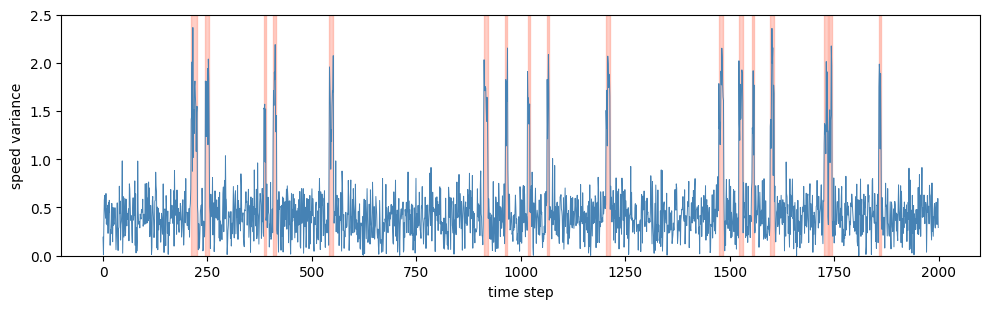

In [4]:
fig, ax = plt.subplots(figsize=(10, 3.2))
ax.plot(crowd.speed_var.values, lw=0.7, color="steelblue")
ax.fill_between(range(len(crowd)), 0, 2.5, where=crowd.abnormal.values, color="tomato", alpha=0.3)
ax.set_ylim(0, 2.5)
ax.set_xlabel("time step")
ax.set_ylabel("speed variance")
plt.tight_layout()
plt.show()

## B. Utility-based agent: stressed patients

Each option is scored by how much it lowers the patient's stress, minus the carbon, water and staff time it uses. The penalty on remaining stress grows with its square, so the agent uses low-impact options for mild stress and calls a nurse only when those are not enough.

In [5]:
OPTIONS = pd.DataFrame(
    [
        ("monitor_only",     0.0,    0.0,  0),
        ("breathing_prompt", 1.0,    0.5,  0),
        ("soothing_music",   1.5,    3.0,  0),
        ("adjust_room",      2.0,  120.0,  2),
        ("nurse_visit",      3.5,   60.0, 10),
    ],
    columns=["option", "relief", "energy_wh", "staff_min"],
).set_index("option")

CO2_PRICE = 0.02
WATER_PRICE = 0.2
STAFF_PRICE = 0.5

def footprint(option):
    kwh = OPTIONS.loc[option, "energy_wh"] / 1000
    return kwh * CO2_PER_KWH * 1000, kwh * WATER_PER_KWH

def utility(stress, option):
    residual = max(0.0, stress - OPTIONS.loc[option, "relief"])
    co2_g, water_l = footprint(option)
    cost = (CO2_PRICE * co2_g + WATER_PRICE * water_l
            + STAFF_PRICE * OPTIONS.loc[option, "staff_min"])
    return -residual ** 2 - cost

def choose_option(stress):
    return max(OPTIONS.index, key=lambda o: utility(stress, o))

policy = pd.DataFrame({"stress": range(0, 11)})
policy["chosen option"] = policy["stress"].apply(choose_option)
policy.set_index("stress")

,chosen option
stress,
0,monitor_only
1,breathing_prompt
2,soothing_music
3,soothing_music
4,nurse_visit
5,nurse_visit
6,nurse_visit
7,nurse_visit
8,nurse_visit


In [6]:
def run_care(policy_fn, stress_levels):
    meter, staff, residual = EcoMeter(), 0, []
    for s in stress_levels:
        option = policy_fn(s)
        relief = max(0.0, OPTIONS.loc[option, "relief"] * rng.normal(1, 0.1))
        residual.append(max(0.0, s - relief))
        meter.use_energy(OPTIONS.loc[option, "energy_wh"])
        staff += OPTIONS.loc[option, "staff_min"]
    out = meter.summary()
    out["staff_min"] = staff
    out["mean_residual_stress"] = round(float(np.mean(residual)), 2)
    return out

stress_levels = rng.uniform(0, 10, 500)

care = pd.DataFrame({
    "utility agent": run_care(choose_option, stress_levels),
    "always nurse": run_care(lambda s: "nurse_visit", stress_levels),
    "always adjust room": run_care(lambda s: "adjust_room", stress_levels),
}).T
care

,energy_kwh,co2_kg,water_l,staff_min,mean_residual_stress
utility agent,19.806,8.319,35.65,3032.0,2.30
always nurse,30.000,12.600,54.00,5000.0,2.05
always adjust room,60.000,25.200,108.00,1000.0,3.14


## C. Goal-based agent: secure school van route

The van has to pick up every student and reach school while avoiding unsafe stops. The agent searches over states made of its current stop and the students already on board. It returns the cheapest route, where cost is driving CO₂ plus a small risk penalty. Stops above a risk of 0.8 are off limits, so Old Road is never used.

In [7]:
names = ["School", "Maple", "Riverside", "Market", "Old Road", "Garden", "Hilltop"]
dist_km = np.array([
    [0.0, 2.1, 3.4, 1.8, 2.9, 2.6, 4.0],
    [2.1, 0.0, 1.5, 2.2, 1.9, 3.0, 3.8],
    [3.4, 1.5, 0.0, 1.6, 2.4, 2.8, 3.1],
    [1.8, 2.2, 1.6, 0.0, 1.2, 2.5, 2.3],
    [2.9, 1.9, 2.4, 1.2, 0.0, 1.7, 2.0],
    [2.6, 3.0, 2.8, 2.5, 1.7, 0.0, 1.9],
    [4.0, 3.8, 3.1, 2.3, 2.0, 1.9, 0.0],
])
risk = np.array([0.0, 0.1, 0.5, 0.2, 0.85, 0.15, 0.3])
pickups = [1, 2, 3, 5, 6]
MAX_RISK = 0.8
RISK_PRICE = 0.05

def plan_route():
    full = (1 << len(pickups)) - 1
    start = (0, 0)
    queue = [(0.0, start, (0,))]
    best = {start: 0.0}
    while queue:
        cost, state, path = heappop(queue)
        stop, done = state
        if stop == 0 and done == full:
            return cost, path
        if cost > best[state]:
            continue
        for nxt in range(len(names)):
            if nxt == stop or risk[nxt] > MAX_RISK:
                continue
            new_done = done
            if nxt in pickups:
                new_done |= 1 << pickups.index(nxt)
            new_cost = cost + dist_km[stop, nxt] * VAN_CO2_PER_KM + RISK_PRICE * risk[nxt]
            new_state = (nxt, new_done)
            if new_cost < best.get(new_state, float("inf")):
                best[new_state] = new_cost
                heappush(queue, (new_cost, new_state, path + (nxt,)))
    return None, None

def route_stats(path):
    km = sum(dist_km[a, b] for a, b in zip(path, path[1:]))
    return {"km": round(km, 2),
            "co2_kg": round(km * VAN_CO2_PER_KM, 3),
            "risk_exposure": round(sum(risk[s] for s in path[1:]), 2)}

fixed_path = (0, 1, 2, 3, 5, 6, 0)
_, planned = plan_route()
print("planned:", " -> ".join(names[i] for i in planned))
print("Old Road used:", 4 in planned)

van = pd.DataFrame({"fixed order": route_stats(fixed_path),
                    "goal-based agent": route_stats(planned)}).T
van

planned: School -> Maple -> Riverside -> Market -> Hilltop -> Garden -> School
Old Road used: False


,km,co2_kg,risk_exposure
fixed order,13.6,3.4,1.25
goal-based agent,12.0,3.0,1.25


In [8]:
saved = route_stats(fixed_path)["co2_kg"] - route_stats(planned)["co2_kg"]
print(f"Saved per trip: {saved:.2f} kg CO2, about {saved * 2 * 180:.0f} kg per school year (2 trips a day, 180 days)")

Saved per trip: 0.40 kg CO2, about 144 kg per school year (2 trips a day, 180 days)


## D. Learning agent: sport activity for young people

A UCB bandit learns, separately for each age group, which nudge gets young people moving. Its reward is the extra active minutes, minus a price on the CO₂ the nudge causes. A sports day adds the most minutes, but its van travel is carbon-heavy, so the agent has to learn when a cheaper nudge is enough.

In [9]:
GROUPS = ["10-12", "13-15", "16-18"]
ACTIONS = ["app_reminder", "peer_challenge", "reward_points", "sports_day"]

GAIN = {
    "app_reminder":   {"10-12": 10, "13-15": 6,  "16-18": 4},
    "peer_challenge": {"10-12": 18, "13-15": 20, "16-18": 6},
    "reward_points":  {"10-12": 14, "13-15": 9,  "16-18": 7},
    "sports_day":     {"10-12": 35, "13-15": 30, "16-18": 25},
}
ACTION_COST = {
    "app_reminder":   (0.5, 0.0),
    "peer_challenge": (2.0, 0.0),
    "reward_points":  (1.0, 0.0),
    "sports_day":     (40.0, 0.8),
}
CARBON_PRICE = 10.0

def action_co2(action):
    wh, km = ACTION_COST[action]
    return wh / 1000 * CO2_PER_KWH + km * VAN_CO2_PER_KM

class UCBAgent:
    def __init__(self):
        keys = [(g, a) for g in GROUPS for a in ACTIONS]
        self.count = {k: 0 for k in keys}
        self.value = {k: 0.0 for k in keys}
        self.t = {g: 0 for g in GROUPS}

    def choose(self, group):
        self.t[group] += 1
        for a in ACTIONS:
            if self.count[(group, a)] == 0:
                return a

        def score(a):
            bonus = np.sqrt(2 * np.log(self.t[group]) / self.count[(group, a)])
            return self.value[(group, a)] + bonus

        return max(ACTIONS, key=score)

    def learn(self, group, action, reward):
        k = (group, action)
        self.count[k] += 1
        self.value[k] += (reward - self.value[k]) / self.count[k]

In [10]:
def run_nudges(choose, agent=None, days=180, per_day=40):
    meter = EcoMeter()
    gained, reward_sum, daily = 0.0, 0.0, []
    for _ in range(days):
        day_reward = 0.0
        for _ in range(per_day):
            group = GROUPS[rng.integers(len(GROUPS))]
            action = choose(group)
            gain = max(0.0, GAIN[action][group] + rng.normal(0, 4))
            reward = gain / 10 - CARBON_PRICE * action_co2(action)
            wh, km = ACTION_COST[action]
            meter.use_energy(wh)
            meter.drive(km)
            gained += gain
            day_reward += reward
            if agent is not None:
                agent.learn(group, action, reward)
        daily.append(day_reward / per_day)
    result = {"active_minutes": round(gained),
              "co2_g": round(meter.co2 * 1000, 1),
              "water_l": round(meter.water, 1),
              "avg_reward": round(float(np.mean(daily)), 3)}
    return result, daily

learner = UCBAgent()
learner_res, learner_curve = run_nudges(learner.choose, agent=learner)
sports_res, sports_curve = run_nudges(lambda g: "sports_day")
app_res, app_curve = run_nudges(lambda g: "app_reminder")

pd.DataFrame({"learning agent": learner_res,
              "always sports day": sports_res,
              "always app reminder": app_res}).T

,active_minutes,co2_g,water_l,avg_reward
learning agent,108470.0,32110.2,30.5,1.462
always sports day,216250.0,1560960.0,518.4,0.835
always app reminder,49338.0,1512.0,6.5,0.683


In [11]:
learned = {g: max(ACTIONS, key=lambda a: learner.value[(g, a)]) for g in GROUPS}
print("learned nudge per group:", learned)

pd.DataFrame({g: {a: round(learner.value[(g, a)], 2) for a in ACTIONS} for g in GROUPS})

learned nudge per group: {'10-12': 'peer_challenge', '13-15': 'peer_challenge', '16-18': 'reward_points'}


,10-12,13-15,16-18
app_reminder,1.03,0.46,0.44
peer_challenge,1.79,1.99,0.58
reward_points,1.36,0.92,0.71
sports_day,1.35,0.59,0.28


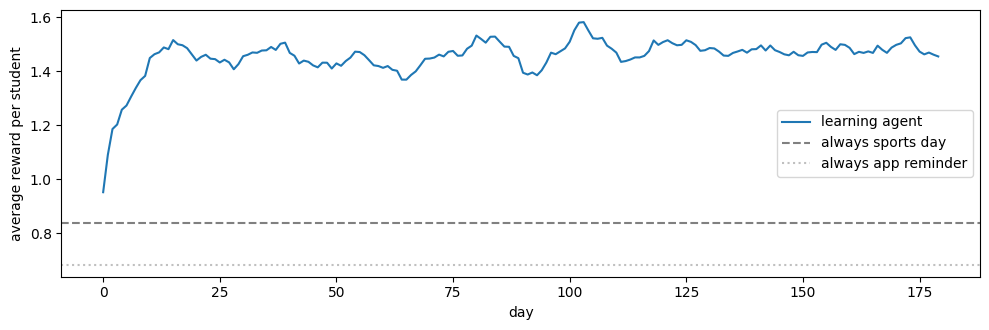

In [12]:
fig, ax = plt.subplots(figsize=(10, 3.4))
ax.plot(pd.Series(learner_curve).rolling(10, min_periods=1).mean(), label="learning agent")
ax.axhline(np.mean(sports_curve), color="gray", ls="--", label="always sports day")
ax.axhline(np.mean(app_curve), color="silver", ls=":", label="always app reminder")
ax.set_xlabel("day")
ax.set_ylabel("average reward per student")
ax.legend()
plt.tight_layout()
plt.show()

## Summary

Each agent is compared with a conventional baseline on CO₂ and water.

In [13]:
def cut(base, eco):
    return round(100 * (1 - eco / base), 1) if base > 0 else 0.0

rows = [
    ("A  crowd monitor", "always-on camera",
     baseline_meter.co2 * 1000, crowd_meter.co2 * 1000,
     baseline_meter.water, crowd_meter.water),
    ("B  patient care", "always nurse visit",
     care.loc["always nurse", "co2_kg"] * 1000, care.loc["utility agent", "co2_kg"] * 1000,
     care.loc["always nurse", "water_l"], care.loc["utility agent", "water_l"]),
    ("C  school van", "fixed stop order",
     route_stats(fixed_path)["co2_kg"] * 1000, route_stats(planned)["co2_kg"] * 1000,
     0.0, 0.0),
    ("D  sport nudges", "always sports day",
     sports_res["co2_g"], learner_res["co2_g"],
     sports_res["water_l"], learner_res["water_l"]),
]
summary = pd.DataFrame(rows, columns=["agent", "baseline", "CO2 baseline (g)", "CO2 eco (g)",
                                      "water baseline (L)", "water eco (L)"])
summary["CO2 cut %"] = [cut(b, e) for b, e in zip(summary["CO2 baseline (g)"], summary["CO2 eco (g)"])]
summary["water cut %"] = [cut(b, e) for b, e in zip(summary["water baseline (L)"], summary["water eco (L)"])]
summary.round(2)

,agent,baseline,CO2 baseline (g),CO2 eco (g),water baseline (L),water eco (L),CO2 cut %,water cut %
0,A crowd monitor,always-on camera,672.0,44.75,2.88,0.19,93.3,93.3
1,B patient care,always nurse visit,12600.0,8319.00,54.00,35.65,34.0,34.0
2,C school van,fixed stop order,3400.0,3000.00,0.00,0.00,11.8,0.0
3,D sport nudges,always sports day,1560960.0,32110.20,518.40,30.50,97.9,94.1
